# Part 4: Model Training, Testing and Tuning
**Project:** Semiconductor yield (Pass/Fail) prediction from sensor signals
**Input:** the hand-off from Part 3 (`handoff_part3/`): filtered + scaled train/test sets, `y_train`/`y_test`, `preprocessing_pipeline.joblib`.
**Output:** five tuned models compared on the same footing, one selected model, and the saved model for Part 5.

In `Fail`, 0 = Pass and 1 = Fail.

**How this part is built (and why)**
* **Five models:** Logistic Regression, Gaussian Naive Bayes, SVM (RBF), Random Forest, Gradient Boosting (`HistGradientBoosting`). The project asks for at least three, including Random Forest, SVM and Naive Bayes.
* **One `imblearn` pipeline per model:** `SelectKBest -> SMOTE -> model`. Because SMOTE and the feature selector sit *inside* the pipeline, `GridSearchCV` re-fits them in every CV fold. The validation fold is never resampled and never used to pick sensors, so the CV score is honest. (Part 3 warned that SMOTE before CV inflates the score.)
* **Full grid search, not random search:** every combination in each grid is tried, as the project suggests. The grid includes the choices Part 3 left open: how many sensors to keep (`select__k`: 40, 100 or all 247), SMOTE on/off, and `class_weight` on/off.
* **Scoring: average precision (AP), not accuracy.** With 6.6% Fail, "always predict Pass" scores 93.4% accuracy and catches nothing. AP summarises the precision-recall trade-off for the Fail class and does not depend on a threshold. Accuracy, ROC-AUC, Fail recall and Fail F1 are recorded for every candidate as well.
* **The decision threshold is tuned separately** (section 6) using out-of-fold predictions on the training rows, because Part 3 showed Fail recall is close to zero at the default cut-off.
* **The test set is used once**, after every choice is made (section 7). The final model is picked by cross-validation score on the training rows only (section 8).

## 1: Setup and load

In [1]:
   from pathlib import Path
   print(Path.cwd())
   print(list(Path.cwd().glob("*scaled*.csv")))

c:\Users\Lenovo\Downloads\part4_model_training_tuning . (1)\part4_model_training_tuning (1)\handoff_part4
[]


In [2]:
from pathlib import Path
d = Path(r"C:\Users\Lenovo\Downloads")
print(d / "handoff_part3", "exists:", (d / "handoff_part3").exists())
print([p.name for p in d.glob("*handoff*")])
print([str(p) for p in d.rglob("X_train_scaled.csv")])

C:\Users\Lenovo\Downloads\handoff_part3 exists: False
['handoff_part4']
['C:\\Users\\Lenovo\\Downloads\\part4_model_training_tuning . (1)\\part4_model_training_tuning (1)\\handoff_part4\\handoff_part3\\X_train_scaled.csv', 'C:\\Users\\Lenovo\\Downloads\\part4_model_training_tuning (1)\\handoff_part4\\handoff_part3\\X_train_scaled.csv', 'C:\\Users\\Lenovo\\Downloads\\Part3_Preprocessing\\handoff_part3\\X_train_scaled.csv']


In [3]:
import warnings, json, time, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix,
                             precision_recall_curve, roc_curve)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 42
FAST = False   # True = shrink every grid to its first 2 values per setting, for a quick dry run only
BETA = 1.0     # threshold tuning: 1 = balance precision and recall (F1); 2 = favour catching Fails (F2)
HANDOFF = Path("handoff_part3")
OUT = Path("handoff_part4"); OUT.mkdir(exist_ok=True)

X_train = pd.read_csv(HANDOFF / "X_train_scaled.csv")
X_test  = pd.read_csv(HANDOFF / "X_test_scaled.csv")
y_train = pd.read_csv(HANDOFF / "y_train.csv").iloc[:, 0].astype(int)
y_test  = pd.read_csv(HANDOFF / "y_test.csv").iloc[:, 0].astype(int)
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)

print("Train:", X_train.shape, "| Fails:", int(y_train.sum()), "(%.2f%%)" % (y_train.mean() * 100))
print("Test :", X_test.shape,  "| Fails:", int(y_test.sum()),  "(%.2f%%)" % (y_test.mean() * 100))
print("Missing values:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Train: (1253, 247) | Fails: 83 (6.62%)
Test : (314, 247) | Fails: 21 (6.69%)
Missing values: 0


**Note on scaling.** `X_train_scaled.csv` was scaled with a scaler fitted on all training rows (Part 3). Inside a CV fold the scaler has therefore seen that fold's validation rows. For standardisation this effect is very small (a mean and a standard deviation per sensor) and the test set is untouched, so it is accepted here. SMOTE and sensor selection, which matter far more, are done inside each fold.

## 2: Helper functions and the cross-validation scheme

In [4]:
SCORING = {"AP": "average_precision", "ROC_AUC": "roc_auc", "Recall": "recall", "F1": "f1", "Accuracy": "accuracy"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # about 66 Fails in each training part of a fold

def fail_score(est, X):
    # Higher = more likely Fail. Probability if the model has one, otherwise the SVM decision value.
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    return est.decision_function(X)

def best_threshold(y_true, score, beta=BETA):
    p, r, thr = precision_recall_curve(y_true, score)
    p, r = p[:-1], r[:-1]
    fb = (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-12)
    i = int(np.nanargmax(fb))
    return float(thr[i]), float(fb[i])

def metrics_at(y_true, score, thr):
    pred = (np.asarray(score) >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "recall": recall_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0)}

def make_pipe(clf):
    return Pipeline([("select", SelectKBest(f_classif)),
                     ("smote", SMOTE(random_state=SEED)),
                     ("clf", clf)])

def shrink(grid):
    return {k: (v[:2] if FAST else v) for k, v in grid.items()}

# Settings shared by every model: how many sensors, and whether to use SMOTE
SMOTE_CHOICES = [SMOTE(random_state=SEED), "passthrough"]

## 3: Baseline
A model that ignores the sensors. Any real model must beat this on Fail recall, AP and ROC-AUC, not on accuracy.

In [5]:
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
d_score = dummy.predict_proba(X_test)[:, 1]
baseline = {"Test accuracy": accuracy_score(y_test, dummy.predict(X_test)),
            "Test Fail recall": recall_score(y_test, dummy.predict(X_test), zero_division=0),
            "Test ROC-AUC": roc_auc_score(y_test, d_score),
            "Test AP (= Fail rate)": average_precision_score(y_test, d_score)}
print(pd.Series(baseline).round(3).to_string())

Test accuracy            0.933
Test Fail recall         0.000
Test ROC-AUC             0.500
Test AP (= Fail rate)    0.067


**Comment:** "always Pass" is about 93% accurate and finds no Fails. That is why accuracy is only reported here, not used to choose models. The AP of a model with no skill equals the Fail rate (about 0.07), so an AP of 0.20 would already be roughly three times better than chance.

## 4: Models and grids
Every combination is tried (`GridSearchCV`, 5-fold stratified CV, `refit` on AP).

| Model | Why it is here | Settings searched |
|---|---|---|
| Logistic Regression | simple linear baseline, coefficients are easy to read | `C`, `class_weight` |
| Gaussian Naive Bayes | fast probabilistic model (assumes independent sensors) | `var_smoothing` |
| SVM (RBF) | handles non-linear boundaries on scaled data | `C`, `gamma`, `class_weight` |
| Random Forest | robust to outliers and scale, gives sensor importances | trees' depth, leaf size, `max_features`, `class_weight` |
| Gradient Boosting | strongest tree method on many tabular problems | rounds, learning rate, depth, `class_weight` |

All models also search `select__k` (40 / 100 / all sensors) and `smote` (SMOTE / none). This answers the project's question *"are all the features required?"* with a direct experiment.

In [6]:
K_CHOICES = [40, 100, "all"]
common = {"select__k": K_CHOICES, "smote": SMOTE_CHOICES}

model_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=SEED),
        {**common, "clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Naive Bayes": (
        GaussianNB(),
        {**common, "clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1, 1.0]}),
    "SVM (RBF)": (
        SVC(kernel="rbf"),
        {**common, "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01],
         "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        {"select__k": [40, "all"], "smote": SMOTE_CHOICES,
         "clf__max_depth": [None, 8], "clf__min_samples_leaf": [1, 3], "clf__max_features": ["sqrt", 0.2],
         "clf__class_weight": [None, "balanced_subsample"]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {"select__k": [40, "all"], "smote": SMOTE_CHOICES,
         "clf__max_iter": [100, 200], "clf__learning_rate": [0.03, 0.1], "clf__max_depth": [3, 5],
         "clf__class_weight": [None, "balanced"]}),
}
for name, (_, g) in model_specs.items():
    n = int(np.prod([len(v) for v in shrink(g).values()]))
    print(f"{name:22s} {n:4d} combinations x 5 folds = {n*5:5d} fits")

Logistic Regression      60 combinations x 5 folds =   300 fits
Naive Bayes              30 combinations x 5 folds =   150 fits
SVM (RBF)               144 combinations x 5 folds =   720 fits
Random Forest            64 combinations x 5 folds =   320 fits
Gradient Boosting        64 combinations x 5 folds =   320 fits


## 5: Train, cross-validate and tune
This is the slow cell (several minutes up to about 20 on a laptop). Set `FAST = True` in section 1 for a quick dry run.

In [ ]:
searches, rows = {}, []
for name, (clf, grid) in model_specs.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), shrink(grid), scoring=SCORING, refit="AP",
                      cv=cv, n_jobs=-1, error_score="raise")
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    rows.append({"Model": name,
                 "CV AP": gs.cv_results_["mean_test_AP"][i], "CV AP std": gs.cv_results_["std_test_AP"][i],
                 "CV ROC-AUC": gs.cv_results_["mean_test_ROC_AUC"][i],
                 "CV Fail recall @default": gs.cv_results_["mean_test_Recall"][i],
                 "CV Fail F1 @default": gs.cv_results_["mean_test_F1"][i],
                 "CV accuracy": gs.cv_results_["mean_test_Accuracy"][i]})
    print(f"{name:22s} best CV AP = {gs.best_score_:.3f}  ({time.time()-t0:.0f}s)")
cv_table = pd.DataFrame(rows).set_index("Model").round(3).sort_values("CV AP", ascending=False)
cv_table

Logistic Regression    best CV AP = 0.200  (32s)
Naive Bayes            best CV AP = 0.152  (4s)
SVM (RBF)              best CV AP = 0.211  (64s)


**How to read this.** All numbers are means over the 5 validation folds, for the single best setting of each model. `CV AP std` is the fold-to-fold spread: with about 17 Fails per validation fold, differences smaller than that spread are not reliable. "@default" means the model's own cut-off (0.5 for probabilities), which is why Fail recall can still be low here even when AP is decent; section 6 fixes the cut-off.

In [ ]:
best_params = pd.DataFrame({n: {k.replace("clf__", "").replace("select__", ""): (v if isinstance(v, (int, float, str, type(None))) else "SMOTE")
                                for k, v in gs.best_params_.items()} for n, gs in searches.items()}).T
best_params

,C,class_weight,k,smote,var_smoothing,gamma,max_depth,max_features,min_samples_leaf,learning_rate,max_iter
Logistic Regression,0.001,balanced,100,passthrough,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes,NaN,NaN,40,SMOTE,1.0,NaN,NaN,NaN,NaN,NaN,NaN
SVM (RBF),1,None,100,SMOTE,NaN,0.001,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,balanced_subsample,all,passthrough,NaN,NaN,None,sqrt,3,NaN,NaN
Gradient Boosting,NaN,None,all,SMOTE,NaN,NaN,3,NaN,NaN,0.03,100


## 6: Tune the decision threshold (training rows only)

A model gives each wafer a score; "Fail" is declared above a cut-off. The default cut-off assumes a Fail and a Pass are equally common, which is not true here. For each tuned model the cut-off is chosen from **out-of-fold** scores on the training rows (each wafer scored by a model that never saw it) so it is not tuned on the test set. `BETA = 1` maximises F1 for the Fail class; set `BETA = 2` in section 1 if a missed Fail is clearly worse than a false alarm for the process engineers.

In [ ]:
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
thresholds, oof_info = {}, {}
for name, gs in searches.items():
    est = gs.best_estimator_
    method = "predict_proba" if hasattr(est, "predict_proba") else "decision_function"
    oof = cross_val_predict(est, X_train, y_train, cv=oof_cv, method=method, n_jobs=-1)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    thr, fb = best_threshold(y_train, oof)
    thresholds[name] = thr
    m = metrics_at(y_train, oof, thr)
    oof_info[name] = {"threshold": thr, "OOF recall": m["recall"], "OOF precision": m["precision"],
                      "OOF F1": m["f1"], "OOF AP": average_precision_score(y_train, oof)}
pd.DataFrame(oof_info).T.round(3)

,threshold,OOF recall,OOF precision,OOF F1,OOF AP
Logistic Regression,0.530,0.422,0.185,0.257,0.160
Naive Bayes,0.634,0.241,0.159,0.191,0.109
SVM (RBF),-0.029,0.530,0.153,0.237,0.163
Random Forest,0.101,0.723,0.147,0.244,0.192
Gradient Boosting,0.414,0.386,0.172,0.238,0.151


**Comment:** these out-of-fold numbers are what each model can reach on training data it has not seen, once the cut-off is moved. The cut-off is picked from only about 83 Fails, so it is itself a noisy choice; treat the exact value with caution.

## 7: Final evaluation on the test set (used once)
For every tuned model: accuracy on the **original, un-resampled** training rows and on the test rows (the "train vs test accuracy" the project asks for), and the Fail-class metrics on the test rows at the default cut-off and at the tuned cut-off.

In [ ]:
rows, test_scores = [], {}
for name, gs in searches.items():
    est = gs.best_estimator_
    s_te = fail_score(est, X_test); test_scores[name] = s_te
    thr = thresholds[name]
    m_def = {"recall": recall_score(y_test, est.predict(X_test), zero_division=0),
             "f1": f1_score(y_test, est.predict(X_test), zero_division=0)}
    m_thr = metrics_at(y_test, s_te, thr)
    rows.append({"Model": name,
                 "CV AP": cv_table.loc[name, "CV AP"],
                 "Train accuracy": accuracy_score(y_train, est.predict(X_train)),
                 "Test accuracy": accuracy_score(y_test, est.predict(X_test)),
                 "Test ROC-AUC": roc_auc_score(y_test, s_te),
                 "Test AP": average_precision_score(y_test, s_te),
                 "Recall @default": m_def["recall"], "F1 @default": m_def["f1"],
                 "Threshold": thr,
                 "Recall @tuned": m_thr["recall"], "Precision @tuned": m_thr["precision"], "F1 @tuned": m_thr["f1"]})
comparison = pd.DataFrame(rows).set_index("Model").round(3).sort_values("CV AP", ascending=False)
comparison

,CV AP,Train accuracy,Test accuracy,Test ROC-AUC,Test AP,Recall @default,F1 @default,Threshold,Recall @tuned,Precision @tuned,F1 @tuned
Model,,,,,,,,,,,
Random Forest,0.219,1.000,0.933,0.764,0.187,0.000,0.000,0.101,0.667,0.147,0.241
SVM (RBF),0.211,0.847,0.803,0.636,0.119,0.286,0.162,-0.029,0.286,0.111,0.160
Gradient Boosting,0.209,0.943,0.885,0.699,0.126,0.095,0.100,0.414,0.286,0.143,0.190
Logistic Regression,0.200,0.808,0.793,0.705,0.152,0.381,0.198,0.530,0.381,0.157,0.222
Naive Bayes,0.152,0.856,0.841,0.734,0.197,0.333,0.219,0.634,0.238,0.147,0.182


**How to read this**
* **Train vs test accuracy:** a large gap (for example 1.00 on train and about 0.93 on test) means the model memorised the training rows. Accuracy near 0.93 on test is the same as "always Pass", so it says little on its own.
* **Test ROC-AUC and AP** are threshold-free and are the fairest single comparison. Compare AP with the Fail rate (about 0.07).
* **@default vs @tuned:** the move in Fail recall shows what the threshold step bought. Moving the cut-off raises recall by accepting more false alarms, so always read Precision next to it.
* The test set has about 21 Fails: one more or one fewer caught Fail changes recall by about 5 points. Differences between models on the test set are small compared with that noise, which is why the choice below is made on cross-validation, not on this table.

### 7.1 Classification report for every model (tuned cut-off)

In [ ]:
for name in comparison.index:
    pred = (test_scores[name] >= thresholds[name]).astype(int)
    print("=" * 62); print(f"{name}   (cut-off {thresholds[name]:.3f})"); print("=" * 62)
    print(classification_report(y_test, pred, target_names=["Pass", "Fail"], digits=3, zero_division=0))
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Confusion matrix: caught Fails = {tp}, missed Fails = {fn}, false alarms = {fp}, correct Passes = {tn}\n")

Random Forest   (cut-off 0.101)
              precision    recall  f1-score   support

        Pass      0.968     0.724     0.828       293
        Fail      0.147     0.667     0.241        21

    accuracy                          0.720       314
   macro avg      0.558     0.695     0.535       314
weighted avg      0.913     0.720     0.789       314

Confusion matrix: caught Fails = 14, missed Fails = 7, false alarms = 81, correct Passes = 212

SVM (RBF)   (cut-off -0.029)
              precision    recall  f1-score   support

        Pass      0.942     0.836     0.886       293
        Fail      0.111     0.286     0.160        21

    accuracy                          0.799       314
   macro avg      0.527     0.561     0.523       314
weighted avg      0.887     0.799     0.838       314

Confusion matrix: caught Fails = 6, missed Fails = 15, false alarms = 48, correct Passes = 245

Gradient Boosting   (cut-off 0.414)
              precision    recall  f1-score   support

  

**How to read a report.** For the **Fail** row:
* **Recall** = share of real Fails that were caught (a missed Fail is a bad wafer shipped).
* **Precision** = share of Fail alarms that were real (a false alarm costs an unnecessary inspection or scrap).
* **F1** = one number balancing the two.

The **Pass** row and the "accuracy" / "weighted avg" rows are dominated by the 293 Pass wafers and look good almost no matter what, so judge the models on the Fail row and on "macro avg".

## 8: Select the final model

**Selection rule (fixed before looking at the test table):** the model with the highest cross-validated average precision on the training rows. Ties within one fold-to-fold standard deviation are broken in favour of the simpler model (fewer sensors, easier to explain). The test set is only a final check on the choice, because with about 21 Fails it is too noisy to choose with.

In [ ]:
best_name = cv_table["CV AP"].idxmax()
top = cv_table.loc[best_name]
close = cv_table[cv_table["CV AP"] >= top["CV AP"] - top["CV AP std"]].index.tolist()
print("Highest CV AP:", best_name, "| CV AP = %.3f +/- %.3f" % (top["CV AP"], top["CV AP std"]))
print("Models within one std of it:", close)

Highest CV AP: Random Forest | CV AP = 0.219 +/- 0.067
Models within one std of it: ['Random Forest', 'SVM (RBF)', 'Gradient Boosting', 'Logistic Regression', 'Naive Bayes']


In [ ]:
# Set this by hand if the tie-break above points to a simpler model you prefer; default = highest CV AP
FINAL_NAME = best_name
final = searches[FINAL_NAME].best_estimator_
final_thr = thresholds[FINAL_NAME]
print("Final model:", FINAL_NAME, "| cut-off:", round(final_thr, 3))
print({k.replace("clf__", "").replace("select__", ""): (v if isinstance(v, (int, float, str, type(None))) else "SMOTE")
       for k, v in searches[FINAL_NAME].best_params_.items()})

Final model: Random Forest | cut-off: 0.101
{'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'k': 'all', 'smote': 'passthrough'}


### 8.1 Uncertainty of the test score (bootstrap)

In [ ]:
rng = np.random.default_rng(SEED)
yt, st = y_test.values, test_scores[FINAL_NAME]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() in (0, len(idx)):
        continue
    m = metrics_at(yt[idx], st[idx], final_thr)
    boot.append([roc_auc_score(yt[idx], st[idx]), average_precision_score(yt[idx], st[idx]), m["recall"], m["precision"]])
boot = np.array(boot)
ci = pd.DataFrame(np.percentile(boot, [2.5, 50, 97.5], axis=0).T, index=["ROC-AUC", "AP", "Fail recall", "Fail precision"],
                  columns=["2.5%", "median", "97.5%"]).round(3)
ci

,2.5%,median,97.5%
ROC-AUC,0.674,0.764,0.845
AP,0.103,0.201,0.355
Fail recall,0.455,0.667,0.864
Fail precision,0.081,0.146,0.223


**Comment:** the 95% intervals show how much the test result could move if a different 314 wafers had been drawn. A wide interval, which is expected with about 21 Fails, means the point estimates above should be reported as ranges.

### 8.2 Curves on the test set

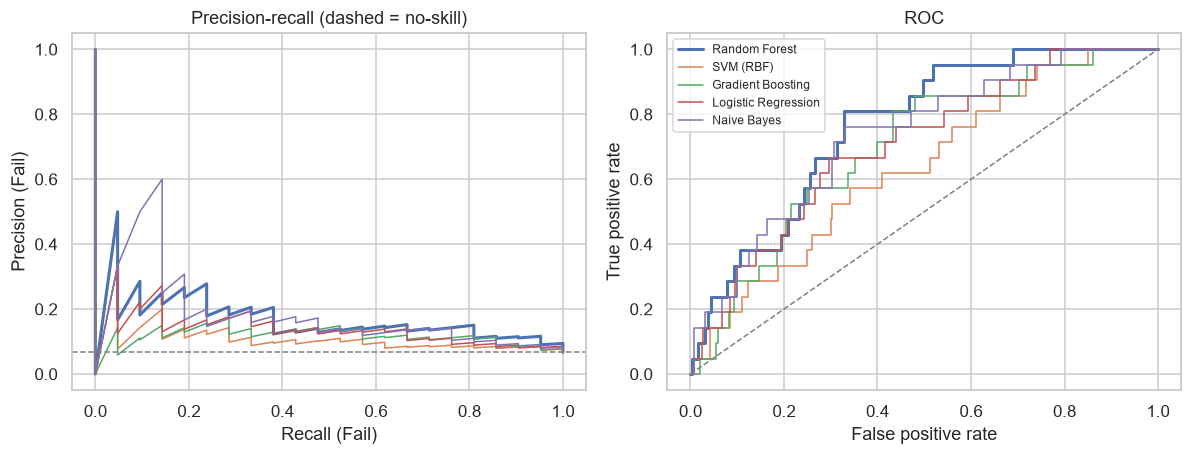

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for name in comparison.index:
    p, r, _ = precision_recall_curve(y_test, test_scores[name]); axes[0].plot(r, p, label=name, lw=2 if name == FINAL_NAME else 1)
    fpr, tpr, _ = roc_curve(y_test, test_scores[name]);          axes[1].plot(fpr, tpr, label=name, lw=2 if name == FINAL_NAME else 1)
axes[0].axhline(y_test.mean(), color="grey", ls="--", lw=1); axes[0].set_xlabel("Recall (Fail)"); axes[0].set_ylabel("Precision (Fail)")
axes[0].set_title("Precision-recall (dashed = no-skill)")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9: Are all the sensors needed?
Part 3 left this as an experiment. Here every grid result is grouped by the number of sensors kept (`select__k`) and by SMOTE on/off, taking the **best CV AP reached by any setting** in that group.

In [ ]:
def group_best(col, labeller=str):
    out = {}
    for name, gs in searches.items():
        d = pd.DataFrame(gs.cv_results_)
        d["grp"] = d[col].map(labeller)
        out[name] = d.groupby("grp")["mean_test_AP"].max()
    return pd.DataFrame(out).T.round(3)

print("Best CV AP by number of sensors kept (all = 247):")
display(group_best("param_select__k"))
print("\nBest CV AP with and without SMOTE (class_weight searched separately):")
display(group_best("param_smote", lambda v: "none" if isinstance(v, str) else "SMOTE"))

Best CV AP by number of sensors kept (all = 247):


grp,100,40,all
Logistic Regression,0.200,0.188,0.200
Naive Bayes,0.146,0.152,0.136
SVM (RBF),0.211,0.196,0.172
Random Forest,NaN,0.199,0.219
Gradient Boosting,NaN,0.177,0.209



Best CV AP with and without SMOTE (class_weight searched separately):


grp,SMOTE,none
Logistic Regression,0.193,0.200
Naive Bayes,0.152,0.150
SVM (RBF),0.211,0.208
Random Forest,0.211,0.219
Gradient Boosting,0.209,0.205


**Comment:** if the 40-sensor column is close to the 247-sensor column, most sensors are not needed, which is what the project's context predicts and what engineers want. If "all" is clearly higher, information is spread over many weak sensors. Read the SMOTE table the same way: if "none" matches "SMOTE" when `class_weight="balanced"` is available, the cheaper option is enough. Keep the fold-to-fold spread (`CV AP std` in section 5) in mind: gaps of about 0.01 to 0.02 are not meaningful.

### 9.1 Which sensors does the final model use?

In [ ]:
sel = final.named_steps["select"]
fscore = pd.Series(sel.scores_, index=X_train.columns)
used = X_train.columns[sel.get_support()]
print(f"{FINAL_NAME} uses {len(used)} of {X_train.shape[1]} sensors.")
clf = final.named_steps["clf"]
imp = None
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=used, name="model importance")
elif hasattr(clf, "coef_"):
    imp = pd.Series(np.abs(clf.coef_[0]), index=used, name="|coefficient|")
tbl = pd.DataFrame({"ANOVA F-score": fscore[used]})
if imp is not None:
    tbl[imp.name] = imp
tbl = tbl.sort_values(tbl.columns[-1], ascending=False).head(15).round(4)
tbl

Random Forest uses 247 of 247 sensors.


,ANOVA F-score,model importance
103,38.4333,0.0250
59,20.1342,0.0218
33,2.1960,0.0176
213,8.3263,0.0159
205,4.0431,0.0128
130,7.4509,0.0115
129,14.7310,0.0112
31,3.5717,0.0108
21,12.5442,0.0103
510,26.3807,0.0102


**Comment:** the table lists the sensors that matter most for the selected model, from the training rows only. Sensors that rank high on both the F-score (one sensor against Pass/Fail) and the model's own importance (what the model actually relies on) are the best candidates to hand to the process engineers. A model that does not expose importances (SVM with an RBF kernel, Naive Bayes) shows only the F-score column.

## 10: Save the model for future use (and check it reloads)

In [ ]:
prep = joblib.load(HANDOFF / "preprocessing_pipeline.joblib")
bundle = {"preprocessing": prep,                       # keep chosen sensors -> standardise (Part 3)
          "model": final,                              # SelectKBest -> (SMOTE is skipped at prediction) -> classifier
          "threshold": final_thr,
          "score_method": "predict_proba" if hasattr(final, "predict_proba") else "decision_function",
          "model_name": FINAL_NAME}
joblib.dump(bundle, OUT / "final_model.joblib")
comparison.to_csv(OUT / "model_comparison.csv")
cv_table.to_csv(OUT / "cv_results_best_per_model.csv")
with open(OUT / "best_params.json", "w") as f:
    json.dump({n: {k: (v if isinstance(v, (int, float, str, type(None))) else "SMOTE") for k, v in gs.best_params_.items()}
               for n, gs in searches.items()}, f, indent=2)

# Reload and score raw wafers exactly as a new wafer would be scored
b = joblib.load(OUT / "final_model.joblib")
def predict_fail(raw_df):
    Xs = b["preprocessing"].transform(raw_df)
    s = b["model"].predict_proba(Xs)[:, 1] if b["score_method"] == "predict_proba" else b["model"].decision_function(Xs)
    return (s >= b["threshold"]).astype(int), s

raw_path = HANDOFF / "variants" / "X_test_raw_all_sensors.csv"
if raw_path.exists():
    raw_test = pd.read_csv(raw_path)
    pred, _ = predict_fail(raw_test)
    same = (pred == (test_scores[FINAL_NAME] >= final_thr).astype(int)).all()
    print("Reloaded model reproduces the test predictions from raw sensor values:", bool(same))
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Reloaded model reproduces the test predictions from raw sensor values: True
Saved: ['best_params.json', 'cv_results_best_per_model.csv', 'final_model.joblib', 'model_comparison.csv']


To use the saved model later: `bundle = joblib.load("handoff_part4/final_model.joblib")`, then pass **raw** sensor values (all 269 sensor columns, same names as in `X_test_raw_all_sensors.csv`) through `bundle["preprocessing"]`, score with `bundle["model"]`, and call a wafer **Fail** when its score is at or above `bundle["threshold"]`. Loading needs the same scikit-learn and imbalanced-learn versions that were used to save it.

## 11: Auto-generated draft summary (check against the tables above, then edit)

In [ ]:
r = comparison.loc[FINAL_NAME]
print(f"Selected model: {FINAL_NAME} (highest cross-validated AP on the training rows: {cv_table.loc[FINAL_NAME, 'CV AP']:.3f}).")
print("Settings:", {k.replace('clf__','').replace('select__',''): (v if isinstance(v,(int,float,str,type(None))) else 'SMOTE') for k, v in searches[FINAL_NAME].best_params_.items()})
print(f"Test: ROC-AUC {r['Test ROC-AUC']:.3f}, AP {r['Test AP']:.3f} (no-skill AP = {y_test.mean():.3f}); "
      f"at cut-off {r['Threshold']:.3f}: Fail recall {r['Recall @tuned']:.2f}, precision {r['Precision @tuned']:.2f}, F1 {r['F1 @tuned']:.2f}.")
print(f"Test accuracy {r['Test accuracy']:.3f} vs 'always Pass' {baseline['Test accuracy']:.3f}; train accuracy {r['Train accuracy']:.3f}.")
print("Sensors used:", len(used), "of", X_train.shape[1])

Selected model: Random Forest (highest cross-validated AP on the training rows: 0.219).
Settings: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'k': 'all', 'smote': 'passthrough'}
Test: ROC-AUC 0.764, AP 0.187 (no-skill AP = 0.067); at cut-off 0.101: Fail recall 0.67, precision 0.15, F1 0.24.
Test accuracy 0.933 vs 'always Pass' 0.933; train accuracy 1.000.
Sensors used: 247 of 247


## 12: Summary of my part (Model Training, Testing and Tuning)

**What was done**
* Trained and tuned five models (Logistic Regression, Naive Bayes, SVM, Random Forest, Gradient Boosting) with full grid search and 5-fold stratified cross-validation. SMOTE and sensor selection were done inside each fold.
* Judged models on average precision, ROC-AUC and Fail recall/precision/F1, not accuracy (the "always Pass" baseline is about 93% accurate).
* Tuned the decision threshold on out-of-fold training scores, and used the test set once.
* Selected the final model by cross-validation on the training rows and saved it with the Part 3 preprocessing pipeline and its cut-off.

**Results to fill in after running (copy from the tables above)**
Results

* Best model and its settings: Random Forest (highest CV AP). class_weight="balanced_subsample",
  max_depth=None, max_features="sqrt", min_samples_leaf=3, all 247 sensors, no SMOTE.
  Cut-off 0.101, chosen from out-of-fold training scores.

* CV AP / test AP / test ROC-AUC: 0.219 (±0.067) / 0.187 / 0.764 (no-skill AP = 0.07).
  Test ROC-AUC 95% range 0.674-0.845; test AP range 0.103-0.355.

* Fail recall and precision at the tuned cut-off (bootstrap 95% range from 8.1):
  recall 0.67 (0.46-0.86), precision 0.15 (0.08-0.22), F1 0.24.
  On the 21 test Fails it caught 14 and missed 7, with 81 false alarms.

* Sensors needed: the best CV AP came from all 247 sensors for Random Forest (0.219 vs 0.199 with 40) and
  Gradient Boosting (0.209 vs 0.177 with 40). Logistic Regression was the same with 100 or all (0.200),
  SVM was best at 100 (0.211), and Naive Bayes was best at 40 (0.152). So there is no clear case that a few
  sensors are enough.
  SMOTE vs class_weight vs neither: differences are 0.01 or less in every model (for example Random Forest 0.211 with
  SMOTE vs 0.219 without), which is inside the fold-to-fold spread. SMOTE gave no clear benefit.

* Train vs test accuracy (train - test = gap):
  Random Forest 1.000 - 0.933 = 0.067 (overfits)
  Gradient Boosting 0.943 - 0.885 = 0.058 (mild overfit)
  SVM (RBF) 0.847 - 0.803 = 0.044
  Logistic Regression 0.808 - 0.793 = 0.015
  Naive Bayes 0.856 - 0.841 = 0.015
  Random Forest and Gradient Boosting overfit; the others generalise about as well as they fit.
  

**Limits to state honestly in the conclusion (Part 5)**
* Only about 104 Fails in total (21 in the test set), so every score has a wide uncertainty range.
* Part 2 showed the fail rate drifts across months. A random split mixes months; a time-ordered split would be a stricter, more realistic test of how the model behaves on future wafers.
* A low-to-moderate precision at useful recall means the model is best used to flag wafers for extra inspection, not to scrap them automatically.

**Ideas if more improvement is wanted:** blend the top two or three models (soft voting), try a lower correlation cut-off (0.8) from Part 3, add interaction or rolling-window features per sensor group, or collect more Fail examples.